<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory spatial data analysis of multidimensional poverty in Bolivia

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

Is poverty in one municipality similar to poverty in its neighbours? This notebook answers that question for the Multidimensional Poverty Index (MPI, 2012) of Bolivia's 339 municipalities, step by step:

1. **Load and map** the data with `geo4bolivia`
2. **Spatial weights and spatial lags**: who are the neighbours, and how poor are they?
3. **Global spatial dependence**: Moran's I
4. **Local spatial dependence**: LISA clusters and outliers
5. **Combined figure**: the Moran scatterplot next to the cluster map

## 0. Setup

In Google Colab the next cell installs the package and the spatial-analysis libraries (a few seconds). Locally, `uv sync` has installed them already.

In [1]:
import importlib.util

missing = [p for p in ["geo4bolivia", "mapclassify", "libpysal", "esda", "splot"] if importlib.util.find_spec(p) is None]
if missing:
    pkgs = " ".join(missing)
    !pip install -q {pkgs}

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from libpysal import weights
from esda.moran import Moran, Moran_Local
from splot.esda import lisa_cluster
from splot.libpysal import plot_spatial_weights

import geo4bolivia as geo

warnings.filterwarnings("ignore", message="Numba not installed")   # mapclassify works without it
sns.set_theme(style="whitegrid")
SEED = 12345

## 1. Load the data

`geo.load(..., geometry=True)` returns the poverty index with the municipal boundaries and names. The MPI runs from 0 to 1, and **higher values mean more poverty**. We add the department of each municipality and a poverty rank (1 = poorest), and project the map to the observatory's equal-area projection, so that distances and areas are in metres.

In [3]:
gdf = geo.load("sdg01", variables="sdg1_2_mpi", years=2012, geometry=True)

units = geo.units("municipality")[["geo_id", "department_id"]]
dep_names = geo.units("department").set_index("geo_id")["name"]
gdf = gdf.merge(units, on="geo_id")
gdf["department"] = gdf["department_id"].map(dep_names)
gdf["rank_mpi"] = gdf["sdg1_2_mpi"].rank(ascending=False, method="min").astype(int)

gdf = gdf[["geo_id", "name", "department", "sdg1_2_mpi", "rank_mpi", "geometry"]].to_crs(geo.config()["equal_area_crs"])
gdf.head()

,geo_id,name,department,sdg1_2_mpi,rank_mpi,geometry
0,BO-01-01-01,Azurduy,Chuquisaca,0.440,4,"POLYGON ((-4787.634 -436502.784, -4737.493 -43..."
1,BO-01-01-02,Tarvita,Chuquisaca,0.380,15,"POLYGON ((-11300.437 -390564.676, -11108.865 -..."
2,BO-01-02-01,Villa Serrano,Chuquisaca,0.199,130,"POLYGON ((12248.489 -294083.78, 12517.521 -293..."
3,BO-01-03-01,Huacareta,Chuquisaca,0.261,62,"POLYGON ((35331.312 -486863.957, 35588.935 -48..."
4,BO-01-03-02,Monteagudo,Chuquisaca,0.166,178,"POLYGON ((26856.895 -447663.773, 26979.738 -44..."


Department boundaries, with a label point inside each, for the maps:

In [4]:
departments = geo.boundaries("department").to_crs(gdf.crs)
departments["label_point"] = departments.representative_point()

## 2. Map the data

A continuous colour scale first, then three classes found by the Fisher-Jenks natural-breaks algorithm.

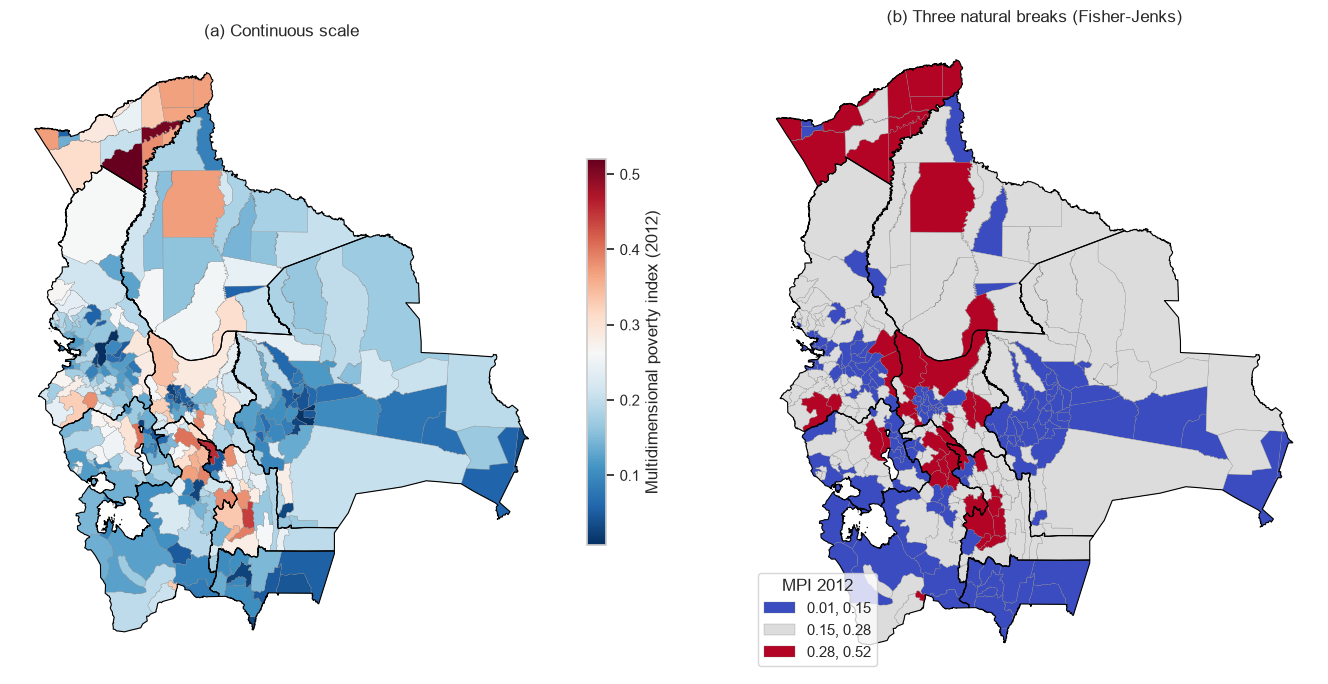

In [5]:
def add_departments(ax, labels=True):
    departments.boundary.plot(ax=ax, color="black", linewidth=0.8)
    if labels:
        for _, row in departments.iterrows():
            ax.annotate(row["name"], xy=(row["label_point"].x, row["label_point"].y), ha="center", fontsize=8,
                        bbox={"facecolor": "white", "alpha": 0.8, "pad": 1.5, "edgecolor": "none"})
    ax.set_axis_off()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
gdf.plot(column="sdg1_2_mpi", cmap="RdBu_r", edgecolor="grey", linewidth=0.2, legend=True,
         legend_kwds={"label": "Multidimensional poverty index (2012)", "shrink": 0.6}, ax=axes[0])
gdf.plot(column="sdg1_2_mpi", scheme="FisherJenks", k=3, cmap="coolwarm", edgecolor="grey", linewidth=0.2,
         legend=True, legend_kwds={"title": "MPI 2012", "loc": "lower left"}, ax=axes[1])
axes[0].set_title("(a) Continuous scale")
axes[1].set_title("(b) Three natural breaks (Fisher-Jenks)")
for ax in axes:
    add_departments(ax, labels=False)
plt.tight_layout()
plt.show()

Poverty is not scattered at random. The poorest municipalities (red) concentrate in Pando, in the far north, and in a belt where Chuquisaca, Potosí and Cochabamba meet. The least poor (blue) are the metropolitan areas of La Paz–El Alto and Cochabamba, the lowlands around Santa Cruz de la Sierra, and Tarija in the south.

## 3. Spatial weights and spatial lags

A **spatial weights matrix** $W$ says who is a neighbour of whom. Here each municipality's neighbours are its 6 nearest municipalities (by the distance between centroids). The matrix is **row-standardised**, so each row sums to one and the neighbours have equal weight.

In [6]:
W = weights.KNN.from_dataframe(gdf, k=6)
W.transform = "r"
print(f"{W.n} municipalities, {W.mean_neighbors:.0f} neighbours each, {W.s0:.0f} = sum of the weights")

339 municipalities, 6 neighbours each, 339 = sum of the weights


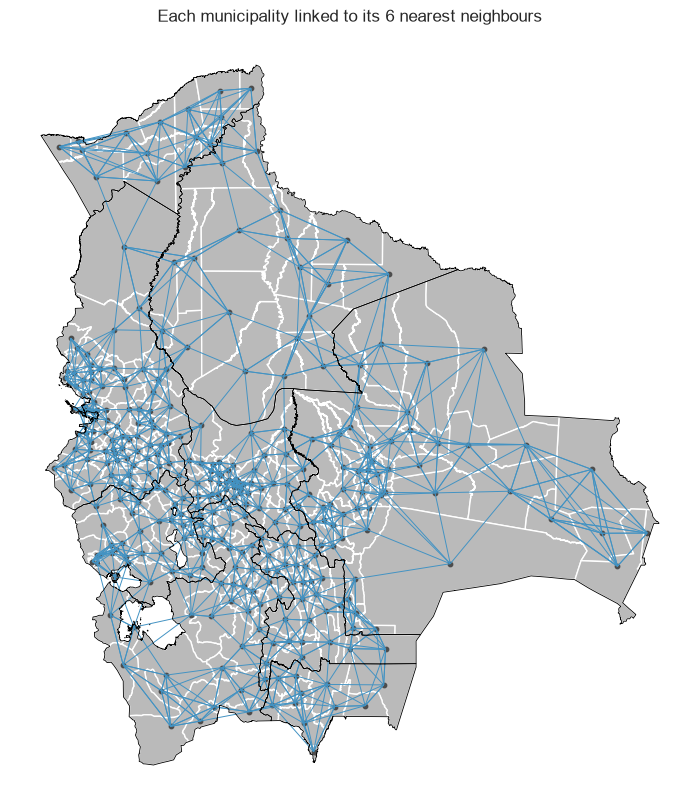

In [7]:
fig, ax = plt.subplots(figsize=(10, 10))
plot_spatial_weights(W, gdf, ax=ax)
departments.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.set_title("Each municipality linked to its 6 nearest neighbours")
plt.show()

The **spatial lag** $Wy$ of the MPI is the average poverty of each municipality's neighbours:

In [8]:
gdf["W_mpi"] = weights.lag_spatial(W, gdf["sdg1_2_mpi"])
gdf[["name", "department", "sdg1_2_mpi", "W_mpi"]].round(3).head(10)

,name,department,sdg1_2_mpi,W_mpi
0,Azurduy,Chuquisaca,0.440,0.318
1,Tarvita,Chuquisaca,0.380,0.310
2,Villa Serrano,Chuquisaca,0.199,0.212
3,Huacareta,Chuquisaca,0.261,0.282
4,Monteagudo,Chuquisaca,0.166,0.252
5,Huacaya,Chuquisaca,0.246,0.162
6,Macharetí,Chuquisaca,0.196,0.154
7,Muyupampa,Chuquisaca,0.186,0.186
8,Camargo,Chuquisaca,0.144,0.277
9,Incahuasi,Chuquisaca,0.394,0.302


For Azurduy, one of the poorest municipalities (MPI 0.44), the average of its 6 neighbours is 0.32: poor, but less so.

## 4. Global spatial dependence

Plotting each municipality's poverty against the poverty of its neighbours shows whether poor municipalities tend to have poor neighbours:

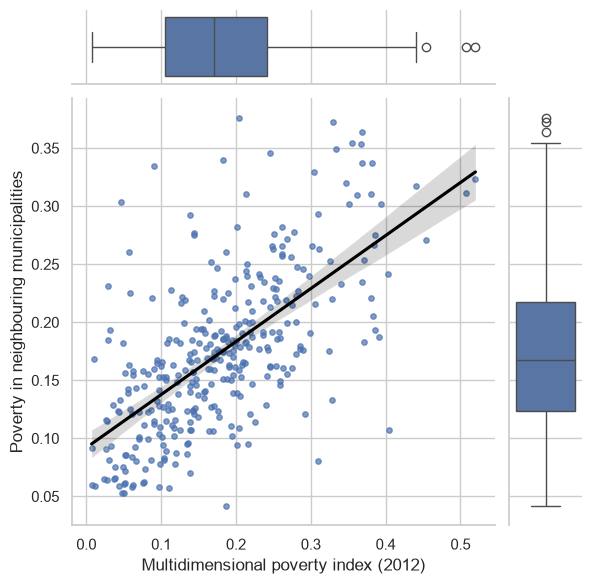

In [9]:
labels = {"sdg1_2_mpi": "Multidimensional poverty index (2012)", "W_mpi": "Poverty in neighbouring municipalities"}

g = sns.JointGrid(data=gdf, x="sdg1_2_mpi", y="W_mpi", height=6)
g.plot_joint(sns.regplot, scatter_kws={"s": 15, "alpha": 0.7}, line_kws={"color": "black"})
g.plot_marginals(sns.boxplot)
g.set_axis_labels(labels["sdg1_2_mpi"], labels["W_mpi"])
plt.show()

**Moran's I** summarises this relationship in one number: with row-standardised weights it is the slope of the regression of the standardised spatial lag on the standardised variable. Values near 0 mean no spatial pattern; positive values mean that similar values cluster. Its pseudo p-value compares it with 999 random reshuffles of the values across the map.

In [10]:
np.random.seed(SEED)
globalMoran = Moran(gdf["sdg1_2_mpi"], W, permutations=999)
moranI = f"{globalMoran.I:.2f}"

print(f"Moran's I = {globalMoran.I:.3f} (expected under no spatial pattern: {globalMoran.EI:.3f})")
print(f"Pseudo p-value (999 permutations) = {globalMoran.p_sim:.3f}; z = {globalMoran.z_sim:.1f}")

Moran's I = 0.457 (expected under no spatial pattern: -0.003)
Pseudo p-value (999 permutations) = 0.001; z = 15.4


Moran's I is 0.46, far above its expected value of about 0 under spatial randomness, and none of the 999 random reshuffles produced a value as large (pseudo p-value 0.001, the smallest possible with 999 permutations). Poverty is strongly and positively spatially autocorrelated: poor municipalities tend to have poor neighbours, and less poor municipalities less poor neighbours.

## 5. Local spatial dependence

Moran's I is one number for the whole country. **Local Moran's I** (LISA, Local Indicators of Spatial Association) computes one statistic per municipality and tests it with permutations. Each significant municipality falls in one of four groups:

| Group | The municipality is | Its neighbours are | Meaning |
| --- | --- | --- | --- |
| High-high | poor | poor | **poverty hotspot** |
| Low-low | less poor | less poor | **cluster of low poverty** |
| High-low | poor | less poor | poor outlier |
| Low-high | less poor | poor | less poor outlier |

In [11]:
moranLocal = Moran_Local(gdf["sdg1_2_mpi"], W, permutations=999, seed=SEED)

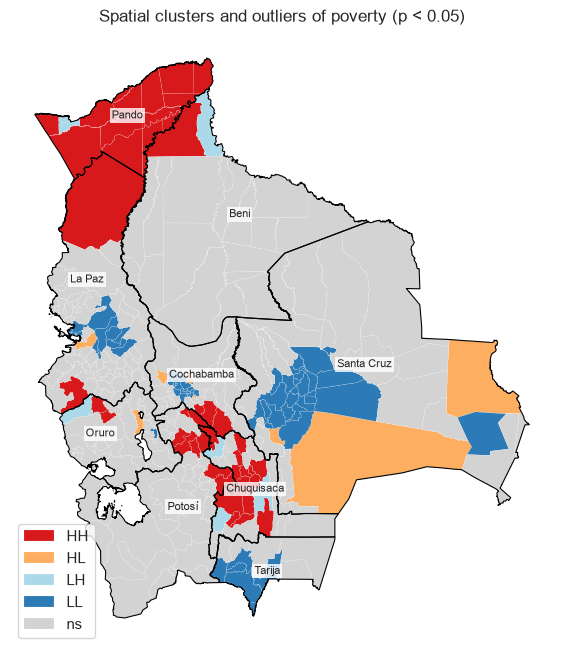

In [12]:
fig, ax = plt.subplots(figsize=(8, 8))
lisa_cluster(moranLocal, gdf, p=0.05, legend_kwds={"loc": "lower left"}, ax=ax)
add_departments(ax)
ax.set_title("Spatial clusters and outliers of poverty (p < 0.05)")
plt.show()

The same classification as a column, to count and list the municipalities in each group:

In [13]:
quadrants = {1: "High-high", 2: "Low-high", 3: "Low-low", 4: "High-low"}
significant = moranLocal.p_sim < 0.05

gdf["lisa_p"] = moranLocal.p_sim
gdf["cluster"] = np.where(significant, pd.Series(moranLocal.q).map(quadrants), "Not significant")
gdf["cluster"].value_counts()

cluster
Not significant    216
Low-low             64
High-high           43
High-low             9
Low-high             7
Name: count, dtype: int64

In [14]:
pd.crosstab(gdf["department"], gdf["cluster"], margins=True, margins_name="Total")

cluster,High-high,High-low,Low-high,Low-low,Not significant,Total
department,,,,,,
Beni,1,0,1,0,17,19
Chuquisaca,14,0,3,0,12,29
Cochabamba,3,3,0,17,24,47
La Paz,2,2,0,14,69,87
Oruro,2,1,1,1,30,35
Pando,13,0,2,0,0,15
Potosí,8,0,0,0,32,40
Santa Cruz,0,3,0,26,27,56
Tarija,0,0,0,6,5,11


The spatial outliers, municipalities that differ significantly from their neighbours:

In [15]:
outliers = gdf["cluster"].isin(["High-low", "Low-high"])
(gdf[outliers].sort_values(["cluster", "sdg1_2_mpi"], ascending=[True, False])
    [["name", "department", "cluster", "sdg1_2_mpi", "W_mpi", "rank_mpi", "lisa_p"]].round(3))

,name,department,cluster,sdg1_2_mpi,W_mpi,rank_mpi,lisa_p
187,El Choro,Oruro,High-low,0.405,0.107,5,0.027
35,Morochata,Cochabamba,High-low,0.309,0.080,34,0.002
319,Postrer Valle,Santa Cruz,High-low,0.225,0.114,95,0.042
152,Tito Yupanqui,La Paz,High-low,0.216,0.095,105,0.010
284,Charagua,Santa Cruz,High-low,0.204,0.108,121,0.023
66,Cuchumuela,Cochabamba,High-low,0.202,0.094,125,0.010
277,San Matías,Santa Cruz,High-low,0.194,0.102,138,0.015
148,Pucarani,La Paz,High-low,0.193,0.110,140,0.032
50,Colomi,Cochabamba,High-low,0.186,0.042,150,0.001
4,Monteagudo,Chuquisaca,Low-high,0.166,0.252,178,0.036


At the 5% level, 123 of the 339 municipalities belong to a significant group:

- **43 poverty hotspots (High-high)**: 13 of Pando's 15 municipalities, 14 in Chuquisaca and 8 in Potosí, plus a few in Cochabamba, La Paz, Oruro and Beni.
- **64 low-poverty clusters (Low-low)**: the metropolitan area of Santa Cruz de la Sierra and its surroundings (26 municipalities), the Cochabamba valley (17), La Paz–El Alto, the shore of Lake Titicaca and the Yungas (14), and Tarija (6).
- **16 outliers**. The 7 Low-high outliers are less poor municipalities surrounded by poorer ones, among them the department capitals Sucre and Cobija, Porvenir next to Cobija, and Guayaramerín (Beni), next to the Pando hotspot. The 9 High-low outliers are poorer municipalities next to less poor ones, such as El Choro (Oruro, MPI 0.41) and Morochata (Cochabamba, 0.31), and the large lowland municipalities of Charagua and San Matías in Santa Cruz.

With 339 local tests, some significant results are expected by chance alone, so treat isolated significant municipalities with care; the large contiguous clusters are the robust finding.

## 6. Combined figure

The Moran scatterplot coloured by LISA group, next to the cluster map. The dashed lines are the means of the MPI and of its spatial lag, which split the plot into the four quadrants.

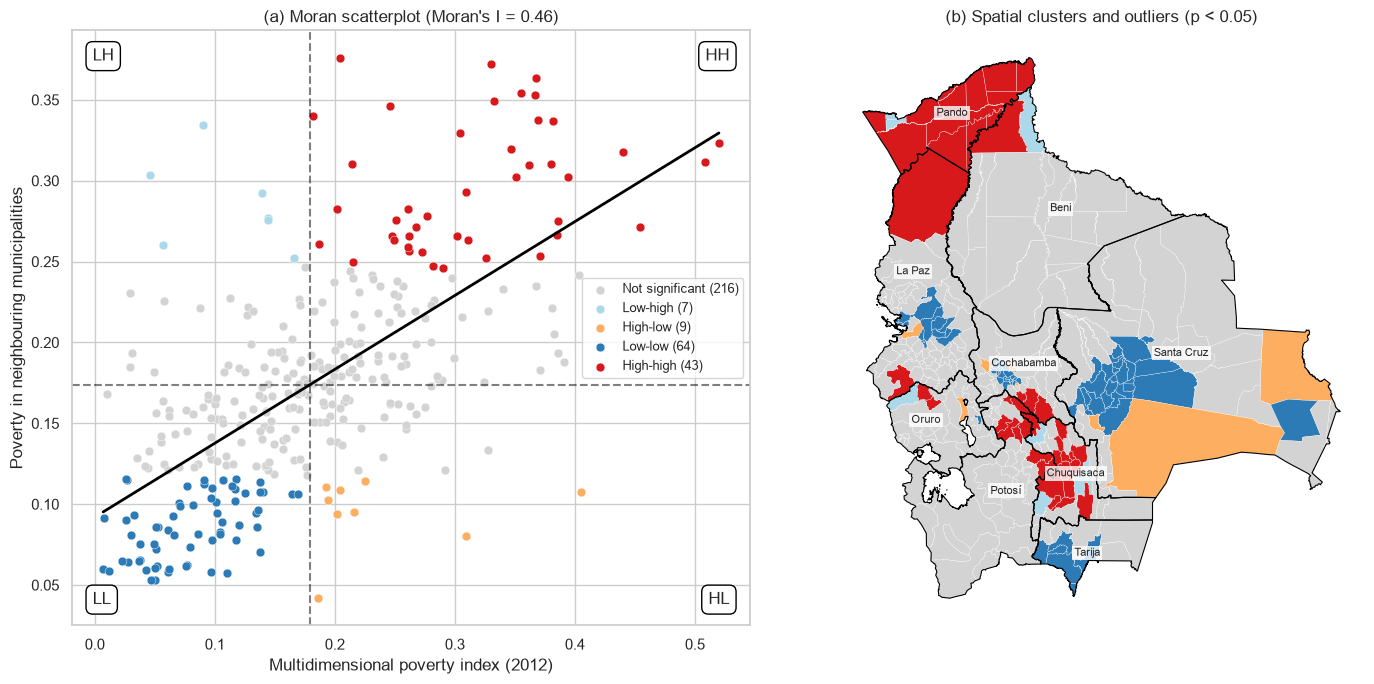

In [16]:
colors = {"High-high": "#d7191c", "High-low": "#fdae61", "Low-high": "#abd9e9", "Low-low": "#2c7bb6",
          "Not significant": "#d3d3d3"}

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1, 1.1]})

# (a) Moran scatterplot
ax = axes[0]
sns.regplot(data=gdf, x="sdg1_2_mpi", y="W_mpi", scatter=False, ci=None, line_kws={"color": "black", "lw": 2}, ax=ax)
for group in ["Not significant", "Low-high", "High-low", "Low-low", "High-high"]:
    d = gdf[gdf["cluster"] == group]
    ax.scatter(d["sdg1_2_mpi"], d["W_mpi"], s=40, color=colors[group], label=f"{group} ({len(d)})",
               edgecolor="white", linewidth=0.3)
x_mean, y_mean = gdf["sdg1_2_mpi"].mean(), gdf["W_mpi"].mean()
ax.axvline(x_mean, color="black", alpha=0.5, linestyle="--")
ax.axhline(y_mean, color="black", alpha=0.5, linestyle="--")
box = dict(boxstyle="round,pad=0.4", fc="white", ec="black", lw=1)
for text, (x, y) in {"HH": (0.97, 0.97), "LH": (0.03, 0.97), "LL": (0.03, 0.03), "HL": (0.97, 0.03)}.items():
    ax.text(x, y, text, transform=ax.transAxes, ha="right" if x > 0.5 else "left",
            va="top" if y > 0.5 else "bottom", bbox=box)
ax.set(xlabel=labels["sdg1_2_mpi"], ylabel=labels["W_mpi"], title=f"(a) Moran scatterplot (Moran's I = {moranI})")
ax.legend(loc="center right", fontsize=9)

# (b) cluster map
ax = axes[1]
gdf.plot(color=gdf["cluster"].map(colors), edgecolor="white", linewidth=0.2, ax=ax)
add_departments(ax)
ax.set_title("(b) Spatial clusters and outliers (p < 0.05)")

plt.tight_layout()
plt.show()

## Summary

- Multidimensional poverty in 2012 is strongly spatially clustered: Moran's I = 0.46 (pseudo p-value 0.001) with 6-nearest-neighbour weights.
- Poverty hotspots are in Pando and on the borders of Chuquisaca, Potosí and Cochabamba; clusters of low poverty surround the main cities (Santa Cruz de la Sierra, Cochabamba, La Paz–El Alto) and Tarija.
- Some capitals (Sucre, Cobija) stand out as less poor islands among poorer neighbours.
- The companion notebook [`esda_dependence`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda_dependence.ipynb) compares map classifications and repeats the analysis at the 10% level; [`eda`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/eda.ipynb) relates poverty to population and night-time lights.